# Simulated data: an agent's specification search

A specification search compares candidate formulas on held-out folds, changes
the current formula when a candidate meets its acceptance rule, and repeats. This study runs that loop with public functions only, on simulated data whose generating process is known, and grades what the
loop ends with against the truth. The page runs the loop step by step on one
frame, then reports the same loop, scripted in
`benches/bench_agent_search.py`, on twenty generating processes.

The search uses each function's reported gain and standard error to decide
which changes to score and accept. Grouped folds evaluate predictions for new
groups; they cannot evaluate the value of knowing an existing group's effect.

This case evaluates a reproducible specification-search policy on simulated data.
The live example prints every decision; the recorded battery then grades the same policy
against twenty known generating processes.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | whether the documented search loop, run without human
  judgement, recovers known generating processes |
| **Observed response** | simulated: continuous, count, binary and positive
  responses across twenty processes |
| **Estimand** | for each process, the true terms, interactions and groups
  the final specification carries, the noise columns it keeps, and its held-out
  squared error relative to that of the true mean function |
| **Units** | counts of terms; a ratio of squared errors |
| **Sampling unit** | one simulated row; in six processes rows share a group |
| **Dependence** | group intercepts or slopes where a process has groups |
| **Split / resampling unit** | whole groups held out where the task is
  prediction for a new group, rows otherwise |
| **Tuning** | `autospec`'s probes, then `tune_mstop` on the task's folds |
| **Uncertainty** | paired fold standard errors on every comparison; one
  training seed per process |
| **Claim type** | methodological: the processes are simulated, so each
  claim grades the loop, not a population |
| **Known reference point** | the generating processes, stated in
  `benches/bench_agent_search.py` and, for the first frame, on this page |
:::


In [1]:
import collections
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

rng = np.random.default_rng(42)
n = 1200
frame = {name: rng.normal(size=n) for name in
         ("x1", "x2", "x3", "x4", "x5", "x6", "x7", "x8")}
# Sparse codes (3 apart): a 0-based code spanning its whole range reads
# as a count (#313) and never reaches the label logic this case shows.
codes = rng.integers(0, 40, n)
frame["g"] = (codes * 3).astype(float)
b_true = rng.normal(scale=1.0, size=40)[codes]
frame["y"] = (2 * np.sin(2 * frame["x1"]) + 1.5 * (frame["x2"] > 0)
              + 0.8 * frame["x1"] * frame["x4"] + b_true
              + rng.normal(scale=0.8, size=n))

kinds = mb.classify_columns(frame, response="y")
display(pl.DataFrame([{"column": c.name, "values": c.levels, "kind": c.kind,
                       "term": c.term} for c in kinds]))
g_evidence = mb.label_evidence("g", frame["g"], frame["y"])
print(g_evidence.sentence)

column,values,kind,term
str,i64,str,str
"""x1""",1200,"""continuous""","""bbs(x1, df=4.0)"""
"""x2""",1200,"""continuous""","""bbs(x2, df=4.0)"""
"""x3""",1200,"""continuous""","""bbs(x3, df=4.0)"""
"""x4""",1200,"""continuous""","""bbs(x4, df=4.0)"""
"""x5""",1200,"""continuous""","""bbs(x5, df=4.0)"""
"""x6""",1200,"""continuous""","""bbs(x6, df=4.0)"""
"""x7""",1200,"""continuous""","""bbs(x7, df=4.0)"""
"""x8""",1200,"""continuous""","""bbs(x8, df=4.0)"""
"""g""",40,"""categorical""","""brandom(g, df=4.0)"""


40 whole-number values behave as labels: the mean response varies between values 9.4 times as much as noise explains (37.2 standard deviations above no signal), and adjacent values differ as much as arbitrary pairs (adjacency ratio 1.09)


## The frame: `classify_columns` and `label_evidence`

The frame has one response, eight measurements `x1` to `x8`, and a column `g`
of whole numbers from 0 to 39. `classify_columns` reads the measurements as
continuous. It reads `g` against the response with `label_evidence`: the mean
response varies between the values of `g`
{eval}`f"{g_evidence.signal_ratio:.0f}"` times as much as sampling noise
explains, and adjacent values differ as much as arbitrary pairs (adjacency
ratio {eval}`f"{g_evidence.adjacency_ratio:.2f}"`). A column that behaves this
way is a grouping code, and it gets `brandom`, one shrunken effect per group.

A whole-number column with twelve or fewer distinct values is read as levels. A whole-number column with more values is read against the response, and a whole-number age, which does not behave as a grouping code, stays a measurement.

In [2]:
first = mb.autospec(frame, "y", budget=250, mstop=300)
finding = next(h for h in first.hygiene if h.kind == "integer-labels")
print("without groups=:", first.folds_description)
print(" ", finding.consequence)

rec = mb.autospec(frame, "y", budget=250, mstop=300, groups="g")
print()
print(rec.report())
moved = [row for row in rec.evidence.get("shapes", ()) if row.chosen != row.incumbent]
moved_text = ", ".join(f"{row.column} to {row.chosen}" for row in moved) or "no term"
leads = rec.evidence.get("interactions", ())
lead_text = (f"{leads[0].left} with {leads[0].right}, carried by {leads[0].term}"
             if leads else "no pair")
mstop_probe = int(rec.mstop)

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 418 is within 5% of the search cap 418; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 243 is within 5% of the search cap 243; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 238 is within 5% of the search cap 243; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 200 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


without groups=: 5 grouped folds holding whole groups of g out (detected: the terms fit it as a grouping; declare folds= or groups= to control the design)
  fitted with brandom rather than a smooth, and detected as a grouping: the probes' folds hold whole groups out, so every measurement scores rows whose group the fit has not seen. Declare folds= to score a different population


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 418 is within 5% of the search cap 418; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 243 is within 5% of the search cap 243; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 238 is within 5% of the search cap 243; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 200 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(



autospec: y ~ bbs(x1, df=4.0) + btree(x2) + brandom(g, df=4.0)

folds: 5 grouped folds holding whole groups of g out (declare folds= for another design)

response: Gaussian (inferred)

data hygiene (no fit -- scans only)
  g: 40 whole-number values behave as labels: the mean response varies between values 9.4 times as much as noise explains (37.2 standard deviations above no signal), and adjacent values differ as much as arbitrary pairs (adjacency ratio 1.09) -- declared as groups: fitted with brandom, and the probes hold whole groups out

family: Gaussian — from the response's dtype; not measured

spread: spread against the covariates: log(residual^2) on 9 design columns over 1200 rows has R^2 0.01; no covariate's |t| clears the 3.3 bar, so the spread is constant in them

shapes (held-out risk, shared folds)
  x1: bbs stands: bbs 2.4890, bols 4.1533 — the best alternative gains less than 2% of the held-out risk and 0.0 < 2 paired fold standard errors
  x2: btree over bbs: btree 2.464

## Measured specification: `autospec(..., groups=)`

Called without `groups=`, `autospec` already fits `g` with `brandom`, and its
hygiene finding names the fold design that goes with a group column: the random
folds its probes use split groups, so each held-out score is for rows whose
group the fit has seen. The question on this frame is prediction for a group
the model has not seen, so the second call declares the group, and every probe
shares folds that hold whole groups out; the report's first line after the
formula says so.

The report is read from the top. The family stays Gaussian, from the response's
type. The shape probe moved {eval}`moved_text`: in the generating process `x2`
enters as a step at zero, which a stump (a tree with one split) fits and a smooth approximates. The
interaction screen reports {eval}`lead_text`, a lead from the training residual
that has to be scored held out before it enters the model. The step count is
{eval}`mstop_probe`.

In [3]:
grouped = mb.grouped_folds(frame["g"], B=5)
held = np.asarray(grouped)[:, 0] == 0


def rows_of(mask):
    return {name: values[mask] for name, values in frame.items()}


start = rec.formula.split("~", 1)[1].strip()
fold_fit = mb.gamboost(f"y ~ {start}", data=rows_of(~held),
                       control=mb.boost_control(mstop_probe, 0.1))
try:
    fold_fit.predict(newdata=rows_of(held))
except ValueError as error:
    print("ValueError:", error)
average = np.asarray(fold_fit.predict(newdata=rows_of(held), unseen_levels="average"))
zero = np.asarray(fold_fit.predict(newdata=rows_of(held), unseen_levels="zero_effect"))
policy_gap = float(np.max(np.abs(average - zero)))

ValueError: unknown Brandom level 30 at observation 0; the code was not observed during fitting. To predict a level the fit never saw as an average group (the mean of the term's level coefficients), pass unseen_levels="average"; for a zero coefficient, the value the ridge penalty shrinks every level towards, pass unseen_levels="zero_effect"


## Unseen groups: `unseen_levels=`

A grouped fold holds out every row of some groups, so each held-out row belongs
to a group the fold's fit never saw, and `brandom` has no coefficient for it.
`predict(newdata=...)` refuses such a row by default, and the error names the
two policies that predict it instead. `unseen_levels="average"` gives the unseen
group the mean of the term's group coefficients, which is the prediction for a
member of an average group. `"zero_effect"` gives it a zero coefficient, which
is what `cvrisk`, the function that estimates held-out risk, computes for a group its fold holds out. The cross-validation
functions use `"average"`. A random intercept's coefficients average close to
zero, and on this fold the two policies' predictions differ by at most
{eval}`f"{policy_gap:.3f}"`. For a random slope they differ more, because
boosting divides the average slope between the fixed term and the group term.

In [4]:
report = mb.term_report(f"y ~ {start}", frame, folds=grouped, mstop=mstop_probe,
                        shapes=False)
print(report)
fit = rec.fit(frame)
residual = frame["y"] - np.asarray(fit.predict()).ravel()
screened = mb.screen_interactions(frame, residual=residual, response="y", groups=["g"])
suggestions = mb.suggest_specifications(report, screened=screened[:2])
display(pl.DataFrame([{"action": s.action, "term": s.term,
                       "expected gain": round(float(s.expected_gain), 4),
                       "basis": s.basis} for s in suggestions]))
idle = [row["term"] for row in report.contributions
        if row.get("measurable", True) and (row["earns"] <= 0 or row["earns"] < 2 * row["se"])]

TermReport(y ~ ..., out-of-fold family risk 2.498; 4 candidate specifications)
  what each term earns by being there:
    bbs(x1, df=4.0)                        +1.993 (se 0.081)
    btree(x2)                             +0.5901 (se 0.067)
    brandom(g, df=4.0)                   -0.01802 (se 0.02)  (it predicts the average group on these folds, so this is what removing it does to the other terms)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 3 fold predictions in this call asked 1 learner(s) to predict outside the range they were fitted on. bbs(x1), covariate x1: 1 below -2.96453 and 1 above 2.91386 (worst 0.12 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.12 training ranges out that is an assumption, not an estimate. Pass term_report(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  with routine_warnings(stacklevel=3, owner=fn.__name__):


action,term,expected gain,basis
str,str,f64,str
"""add""","""x1 x x4""",0.2924,"""detected"""
"""add""","""x1 x x4""",0.2924,"""detected"""
"""add""","""x1 x x4""",0.2924,"""detected"""
"""add""","""x7 x x8""",0.0069,"""detected"""
"""add""","""x7 x x8""",0.0069,"""detected"""
"""add""","""x7 x x8""",0.0069,"""detected"""


## Term contributions: `term_report` and `suggest_specifications`

`term_report` refits the specification without each term, on the same grouped
folds. Each gain carries `se`, the standard error of the paired fold
differences, so it is read against its noise: {eval}`len(idle)` terms have a gain smaller
than two standard errors. The pure-noise columns are not in the specification
to be judged: `autospec` dropped the terms under 1% of the tuned fit's risk
reduction before recommending it, having checked that dropping them does not
raise the held-out risk (its report lists them under `terms:`). The
group term is reported as not measurable, meaning that its held-out gain under grouped folds is zero. On folds that hold every group out, `brandom(g)`
predicts the average group for every held-out row, so removing it changes
nothing held out, whatever the groups' differences are.

`suggest_specifications` turns the report and the screen into changes: a removal
for each term whose gain the folds cannot tell from zero, one joint removal of
all of them, and the interaction the screen detected, written as the term its
columns call for. Gains carry a standard error, so a shape change worth a thousandth of the risk is not ranked above a detected interaction many times larger. The group term is not suggested for removal on these folds, where its measured gain is zero by construction.

In [5]:
def accept(rows):
    """The loop's rule: a change that beats the current specification by two
    standard errors, or else a removal whose cost is within two standard errors."""
    scored = rows[1:]
    better = [r for r in scored if r["change"] < -2 * r["change se"]]
    removals = [r for r in scored if r["specification"].startswith("drop")
                and r["change"] < 2 * r["change se"]]
    joint = [r for r in removals if "terms that earn" in r["specification"]]
    if better:
        return min(better, key=lambda r: r["change"])
    return joint[0] if joint else (min(removals, key=lambda r: r["change"]) if removals else None)
# Reuse the declared folds so comparisons differ by model, not by split.
def table(rows):
    return pl.DataFrame([{"specification": r["specification"],
                          "out-of-fold risk": round(r["out-of-fold risk"], 4),
                          "change": round(r["change"], 4),
                          "standard error": round(r["change se"], 4)} for r in rows])

candidates = {"current": start}

for s in suggestions:
    if s.specification and s.action in ("add", "drop"):
        candidates.setdefault(f"{s.action} {s.term}", s.specification)

round_one = mb.compare_specifications(candidates, frame, "y", folds=grouped, mstop=mstop_probe)

display(table(round_one))

first_pick = accept(round_one)

spec = first_pick["rhs"] if first_pick else start


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 5 fold predictions in this call asked 3 learner(s) to predict outside the range they were fitted on. bbs(x7, df=2.5, knots=5) %X% bbs(x8, df=2.5, knots=5), covariate x7: 1 above 3.1167 (worst 0.15 training ranges out); bbs(x1), covariate x1: 1 below -2.96453 and 1 above 2.91386 (worst 0.12 training ranges out); bbs(x1, df=2.5, knots=5) %X% bbs(x4, df=2.5, knots=5), covariate x1: 1 below -2.96453 and 1 above 2.91386 (worst 0.12 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.15 training ranges out that is an assumption, not an estimate. Pass compare_specifications(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  with routine_warnings(stacklevel=3, owner=f

specification,out-of-fold risk,change,standard error
str,f64,f64,f64
"""current""",2.4983,0.0,0.0
"""add x1 x x4""",1.8579,-0.6404,0.1342
"""add x7 x x8""",2.5004,0.0021,0.0054


In [6]:
report_two = mb.term_report(f"y ~ {spec}", frame, folds=grouped, mstop=mstop_probe, shapes=False)

second = {"current": spec}

for s in mb.suggest_specifications(report_two):
    if s.specification and s.action == "drop":
        second.setdefault(f"drop {s.term}", s.specification)

round_two = mb.compare_specifications(second, frame, "y", folds=grouped, mstop=mstop_probe)

display(table(round_two))

second_pick = accept(round_two)

final_spec = second_pick["rhs"] if second_pick else spec

print("final:", final_spec)

first_change = first_pick["specification"] if first_pick else "nothing"

second_change = second_pick["specification"] if second_pick else "nothing"


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 8 fold predictions in this call asked 2 learner(s) to predict outside the range they were fitted on. bbs(x1, df=2.5, knots=5) %X% bbs(x4, df=2.5, knots=5), covariate x1: 1 below -2.96453 and 1 above 2.91386 (worst 0.12 training ranges out); bbs(x1), covariate x1: 1 below -2.96453 and 1 above 2.91386 (worst 0.12 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.12 training ranges out that is an assumption, not an estimate. Pass term_report(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  with routine_warnings(stacklevel=3, owner=fn.__name__):
/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:187: ExtrapolationWarning: 2 fold predicti

specification,out-of-fold risk,change,standard error
str,f64,f64,f64
"""current""",1.8579,0.0,0.0


final: bbs(x1, df=4.0) + btree(x2) + brandom(g, df=4.0) + bbs(x1, df=2.5, knots=5) %X% bbs(x4, df=2.5, knots=5)


(scoring-the-changes-compare-specifications)=
## Candidate scores: `compare_specifications`

`compare_specifications` scores every candidate on the same grouped folds, and
each row carries `change se`, the standard error of its paired difference from
the current specification. The loop's rule is: accept a change
that lowers the risk by more than two standard errors, and otherwise a removal
whose cost is within two standard errors, since the folds cannot tell the
smaller specification from the larger. The first accepted change is
{eval}`first_change`. On the new specification, the next accepted change is {eval}`second_change`.

In [7]:
tuning = mb.tune_mstop(f"y ~ {final_spec}", frame, folds=grouped, start=mstop_probe)
print(tuning.sentence)
final_score = mb.cv_risk(final_spec, frame, "y", folds=grouped, mstop=tuning.mstop)
final_fit = mb.gamboost(f"y ~ {final_spec}", data=frame,
                        control=mb.boost_control(tuning.mstop, 0.1))
counts = collections.Counter(final_fit.selected)
display(pl.DataFrame({"learner": list(counts), "updates": list(counts.values())})
        .sort("updates", descending=True))

group_effect = np.asarray(final_fit.partial_effects(which=["g"])["g"][1])
levels = np.unique(frame["g"])
g_hat = np.array([group_effect[frame["g"] == level].mean() for level in levels])
g_true = np.array([b_true[frame["g"] == level][0] for level in levels])
group_corr = float(np.corrcoef(g_hat, g_true)[0, 1])
group_sd_ratio = float(np.std(g_hat) / np.std(g_true))
truth_rng = np.random.default_rng(42)
_ = [truth_rng.normal(size=n) for _ in range(8)]
_ = truth_rng.integers(0, 40, n)
_ = truth_rng.normal(scale=1.0, size=40)
noise_draw = truth_rng.normal(scale=0.8, size=n)
floor = float(np.var(noise_draw) + np.var(b_true))
print(f"grouped-fold score {final_score:.3f}; floor for a new group {floor:.3f}; "
      f"group recovery correlation {group_corr:.3f}")

the risk was still falling at 590, so the grid was extended to 9440; the cross-validated risk turns at 4628 of 9440 iterations tried


/Users/fcela/src/public_github/mboostrs/python/mboostrs/explore.py:978: ExtrapolationWarning: 2 fold predictions in this call asked 2 learner(s) to predict outside the range they were fitted on. bbs(x1, df=2.5, knots=5) %X% bbs(x4, df=2.5, knots=5), covariate x1: 1 below -2.96453 and 1 above 2.91386 (worst 0.12 training ranges out); bbs(x1), covariate x1: 1 below -2.96453 and 1 above 2.91386 (worst 0.12 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.12 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  forward_extrapolation(extrapolated, stacklevel=2)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): brandom(g): 39.3 of 40 df aft

learner,updates
str,i64
"""x2""",2117
"""x1""",1199
"""g""",828
"""bbs(x1, df=2.5, knots=5) %X% b…",484


grouped-fold score 1.788; floor for a new group 1.740; group recovery correlation 0.985


(step-count-and-the-grade-tune-mstop)=
## Stopping iteration: `tune_mstop`

`tune_mstop` cross-validates the step count on the grouped folds and doubles
the grid while the risk is still falling at its end; its selected iteration and stopping-grid report are printed by the call. The generating process was

$$y = 2\sin(2x_1) + 1.5\,(x_2 > 0) + 0.8\,x_1 x_4 + b_g + \varepsilon,
\qquad b_g \sim N(0, 1),\ \ \varepsilon \sim N(0, 0.8^2),$$

with $x_3$ and $x_5$ to $x_8$ pure noise and $g$ a 40-level grouping. The final
specification is {eval}`final_spec`, fitted for {eval}`tuning.mstop` steps. It
carries the sine term, the step in `x2`, the product interaction and the group,
and none of the noise columns. The fitted group effects correlate at
{eval}`f"{group_corr:.3f}"` with the true ones, at
{eval}`f"{group_sd_ratio:.2f}"` of their spread, which is the shrinkage a random
effect should show. Its grouped-fold squared error is
{eval}`f"{final_score:.2f}"`, against {eval}`f"{floor:.2f}"` for the true mean
function on a new group, the variance of the noise plus that of the group
effects, which nothing can predict for a group not seen.

In [8]:
bench = json.loads(Path("bench_agent_search.json").read_text())
results = bench["results"]
runs = pl.DataFrame([{
    "process": r["scenario"],
    "signal": f"{len(r['signal_found'])}/{len(r['signal'])}",
    "interactions": f"{len(r['pairs_found'])}/{len(r['pairs'])}",
    "groups": f"{len(r['groups_found'])}/{len(r['groups'])}",
    "noise kept": f"{len(r['noise_in_formula'])}/{r['noise']}",
    "family": r["family"] + ("" if r["family_ok"] else " (not defensible)"),
    "excess squared error": round(r["excess"], 3),
} for r in results])
display(runs)

n_processes = len(results)
all_signal = sum(len(r["signal_found"]) == len(r["signal"]) for r in results)
with_pairs = [r for r in results if r["pairs"]]
pairs_found = sum(len(r["pairs_found"]) == len(r["pairs"]) for r in with_pairs)
with_groups = [r for r in results if r["groups"]]
groups_found = sum(len(r["groups_found"]) == len(r["groups"]) for r in with_groups)
noise_free = sum(not r["noise_in_formula"] for r in results)
families_ok = sum(r["family_ok"] for r in results)
extra_pairs = sum(bool(r["extra_pairs"]) for r in results)
median_excess = float(np.median([r["excess"] for r in results]))
worst = max(results, key=lambda r: r["excess"])
missed_pairs = [r["scenario"] for r in with_pairs if len(r["pairs_found"]) < len(r["pairs"])]

process,signal,interactions,groups,noise kept,family,excess squared error
str,str,str,str,str,str,f64
"""notebook""","""2/2""","""1/1""","""1/1""","""0/5""","""Gaussian""",0.021
"""negbin_sites""","""2/2""","""0/0""","""0/1""","""0/3""","""NBinomial""",-0.021
"""varying_binary""","""2/2""","""1/1""","""0/0""","""0/2""","""Gaussian""",0.013
"""random_slopes""","""2/2""","""0/1""","""1/1""","""0/2""","""Gaussian""",-0.002
"""many_noise""","""3/3""","""0/0""","""0/0""","""0/27""","""Gaussian""",0.027
…,…,…,…,…,…,…
"""exposure""","""2/2""","""0/0""","""0/0""","""0/1""","""Poisson""",0.01
"""zero_inflated""","""2/2""","""0/0""","""0/0""","""0/1""","""NBinomial""",0.061
"""gamma""","""2/2""","""0/0""","""0/0""","""0/1""","""GammaReg""",0.005


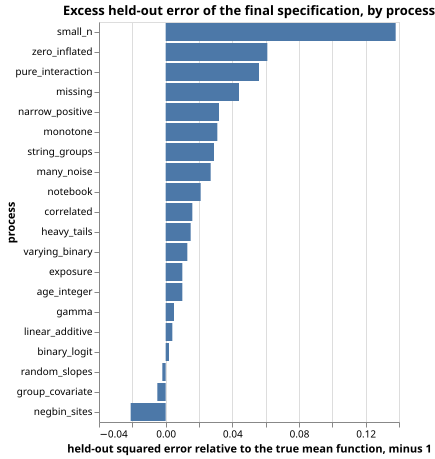

In [9]:
alt.Chart(runs).mark_bar().encode(
    x=alt.X("excess squared error").title(
        "held-out squared error relative to the true mean function, minus 1"),
    y=alt.Y("process").sort("-x"),
    tooltip=["process", "signal", "interactions", "groups", "noise kept", "family",
             "excess squared error"],
).properties(title="Excess held-out error of the final specification, by process")

(twenty-generating-processes-benches-bench-agent-search-py)=
## Twenty generating processes

The script runs the same loop on twenty processes with different modelling
difficulties: groups
coded as whole numbers and as text, random slopes, a group-level covariate,
thirty columns of which three matter, a near-duplicate predictor, a binary
response with an interaction, counts with overdispersion, exposure and excess
zeros, a positive skewed response, a positive response that varies by a
percent of its level, heavy-tailed noise, missing values, 150 rows, and a
whole-number age. The test frame has 4000 rows, and for a grouped task its
groups are ones the fit never saw.

Across the {eval}`n_processes` processes, the final specification carries every
true main effect in {eval}`all_signal`, every generating interaction in
{eval}`pairs_found` of the {eval}`len(with_pairs)` that have one, and fits every
group as a group in {eval}`groups_found` of {eval}`len(with_groups)`. It keeps
no noise column in {eval}`noise_free`, its family is defensible in
{eval}`families_ok`, and it adds a spurious interaction in
{eval}`extra_pairs`. The median excess held-out error is
{eval}`f"{median_excess:.1%}"`; the largest, {eval}`f"{worst['excess']:.1%}"`, is
{eval}`worst["scenario"]`.

The interaction the loop misses is in {eval}`", ".join(missed_pairs) or "none"`.
For `random_slopes`, grouped validation cannot reward the term: a new
clinic's slope cannot be predicted, so on folds that hold clinics out a random
slope term cannot lower the error, and no rule that accepts changes by their
held-out gain will accept it. Folds that keep clinics together can measure it,
for the different task of predicting rows from clinics already seen.

## Limitations

The loop's acceptance rule is a policy, and a different one changes what it
ends with. Two standard errors of paired fold differences on five folds is a
rough test, and the loop applies it to many candidates in turn; the best of
many comparisons is optimistic, and nothing here corrects for that. A
specification the loop accepts has to be checked on data it never scored
against before a claim rests on it.

Each process was drawn once, with one training seed, so a process where the
loop succeeds could fail on another draw; the table reports twenty examples rather than a repeated-sampling error
rate. The processes were chosen to exercise particular modelling difficulties,
so their results do not estimate performance over an arbitrary collection of
applications.

Three processes carry structure the library cannot fit. `exposure` is counts
over unequal hours, which is an offset `log(hours)` that differs by row;
`gamboost` accepts one offset for all rows, so the loop fits `hours` as a
smooth and gets close. `heavy_tails` has noise
with infinite variance, and `autospec` does not measure robust losses, so the
family stays Gaussian. `zero_inflated` has structural zeros, which a
zero-inflated family models and the probe approximates with a negative
binomial.